In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)

In [9]:
#CLEAN DATA 

networth = pd.read_csv("networth.csv")
top100 = pd.read_csv("hot100.csv")

plant = {0: "Non Industry Plant", 
        1: "Industry Plant"}

networth["isPlant"] = networth["IndustryPlant"].replace(plant)

#ML INFO
songs = {"Morgan Wallen":"Last Thing You Need", 
         "Tame Impala":"Dracula",
         "Bruno Mars":"Risk It All",
         "Ella Langley":"Choosin' Texas",
         "Steve Lacy":"Oh Yeah?",
         "Olivia Rodrigo":"Stupid Song",
         "Sam Fender":"Rein Me in",
         "Shaboozey":"Cowgirl",
         "Luke Combs":"Rethink Some Things",
         "ADELA":"Nicole Kidman", 
         "Jamie Miller":"Babydoll",
         "Cameron Whitcomb":"Kingdom Of Fear",
         "Taylor Swift":"Patient Zero",
         "JENNIE":"Dracula",
         "Malcolm Todd":"Earrings",
         "sombr":"My Body Isn't Ready",
         "Lainey Wilson":'"Phone, Keys, Wallet"',
         "Yung Miami":"Spend Dat",
         "Beyonce":"Morning Dew (Donk)",
         "Audrey Hobert":"Sue Me",
         "Ty Dolla $ign":"Cinderella",
         "Olivia Dean":"Rein Me in",
         "Stella Lefty":"Boston",
         "Burna Boy":"Dai Dai (FIFA World Cup Official Song 2026)"}

top100 = top100[top100["Song"].isin(songs.values())]
top100 = top100[top100["Artist"].str.contains('|'.join(songs.keys()))]

df = pd.merge(networth, top100, on="Artist", how="inner")
df = df.replace("-", np.nan)

df 

/var/folders/sl/yk5zr6ld6jx33h4vkrltgt8h0000gn/T/ipykernel_53207/3117732430.py:4: DtypeWarning: Columns (6: Weeks in Charts) have mixed types. Specify dtype option on import or set low_memory=False.
  top100 = pd.read_csv("hot100.csv")


,Networth,Artist,IndustryPlant,isPlant,Date,Song,Rank,Last Week,Peak Position,Weeks in Charts,Image URL
0,35000000,Morgan Wallen,0,Non Industry Plant,2026-09-30,Last Thing You Need,9,NaN,9,NaN,https://charts-static.billboard.com/img/2016/0...
1,35000000,Morgan Wallen,0,Non Industry Plant,2026-10-07,Last Thing You Need,13,9,9,NaN,https://charts-static.billboard.com/img/2016/0...
2,35000000,Morgan Wallen,0,Non Industry Plant,2026-10-21,Last Thing You Need,15,16,9,NaN,https://charts-static.billboard.com/img/2016/0...
3,35000000,Morgan Wallen,0,Non Industry Plant,2026-10-28,Last Thing You Need,21,15,9,NaN,https://charts-static.billboard.com/img/2016/0...
4,175000000,Bruno Mars,0,Non Industry Plant,2026-03-11,Risk It All,4,NaN,4,1,https://charts-static.billboard.com/img/2010/0...
...,...,...,...,...,...,...,...,...,...,...,...
303,10000000,Stella Lefty,1,Industry Plant,2026-09-23,Boston,2,2,2,NaN,https://charts-static.billboard.com/img/2026/0...
304,10000000,Stella Lefty,1,Industry Plant,2026-09-30,Boston,2,2,2,NaN,https://charts-static.billboard.com/img/2026/0...
305,10000000,Stella Lefty,1,Industry Plant,2026-10-07,Boston,6,2,2,NaN,https://charts-static.billboard.com/img/2026/0...
306,10000000,Stella Lefty,1,Industry Plant,2026-10-21,Boston,3,3,2,NaN,https://charts-static.billboard.com/img/2026/0...


In [4]:
# DATA_PATH = 

# try:
#     df = pd.read_csv(DATA_PATH)
#     USING_SYNTHETIC = False
#     print(f'Loaded {DATA_PATH}: {df.shape[0]} rows, {df.shape[1]} columns')
# except FileNotFoundError:
#     USING_SYNTHETIC = True
#     print('WARNING: file not found, using SYNTHETIC demo data. Do not report these results.')
#     rng = np.random.default_rng(RANDOM_STATE)
#     n = 300
#     net_worth = rng.lognormal(mean=2.5, sigma=1.2, size=n)
#     connections = rng.poisson(lam=6, size=n)
#     major_label = rng.binomial(1, 0.5, size=n)
#     playlists = rng.lognormal(mean=6, sigma=0.8, size=n)
#     signal = 0.8 * np.log1p(net_worth) + 0.5 * connections + 2.0 * major_label + 0.002 * playlists
#     weeks = np.clip(np.round(signal + rng.normal(0, 4, size=n)), 1, None)
#     df = pd.DataFrame({
#         'artist': [f'Artist {i}' for i in range(n)],
#         'weeks_on_chart': weeks,
#         'net_worth_millions': net_worth,
#         'industry_connections': connections,
#         'major_label': major_label,
#         'num_playlists': playlists.round(),
#     })

# df.head()

In [10]:
TARGET = 'Weeks in Charts'

print(df.info())
print()
print('Missing values per column:')
print(df.isna().sum())
print()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 308 entries, 0 to 307
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Networth         308 non-null    int64 
 1   Artist           308 non-null    str   
 2   IndustryPlant    308 non-null    int64 
 3   isPlant          308 non-null    object
 4   Date             308 non-null    str   
 5   Song             308 non-null    str   
 6   Rank             308 non-null    int64 
 7   Last Week        284 non-null    str   
 8   Peak Position    308 non-null    int64 
 9   Weeks in Charts  216 non-null    object
 10  Image URL        308 non-null    str   
dtypes: int64(4), object(2), str(5)
memory usage: 26.6+ KB
None

Missing values per column:
Networth            0
Artist              0
IndustryPlant       0
isPlant             0
Date                0
Song                0
Rank                0
Last Week          24
Peak Position       0
Weeks in Charts    92
Image URL

,Networth,IndustryPlant,Rank,Peak Position
count,3.080000e+02,308.000000,308.000000,308.000000
mean,9.431331e+07,0.409091,32.938312,25.392857
std,2.740936e+08,0.492466,28.263063,25.780801
min,1.500000e+06,0.000000,1.000000,1.000000
25%,4.000000e+06,0.000000,11.000000,4.000000
50%,1.000000e+07,0.000000,25.000000,19.000000
75%,3.500000e+07,1.000000,51.500000,42.000000
max,1.800000e+09,1.000000,100.000000,98.000000


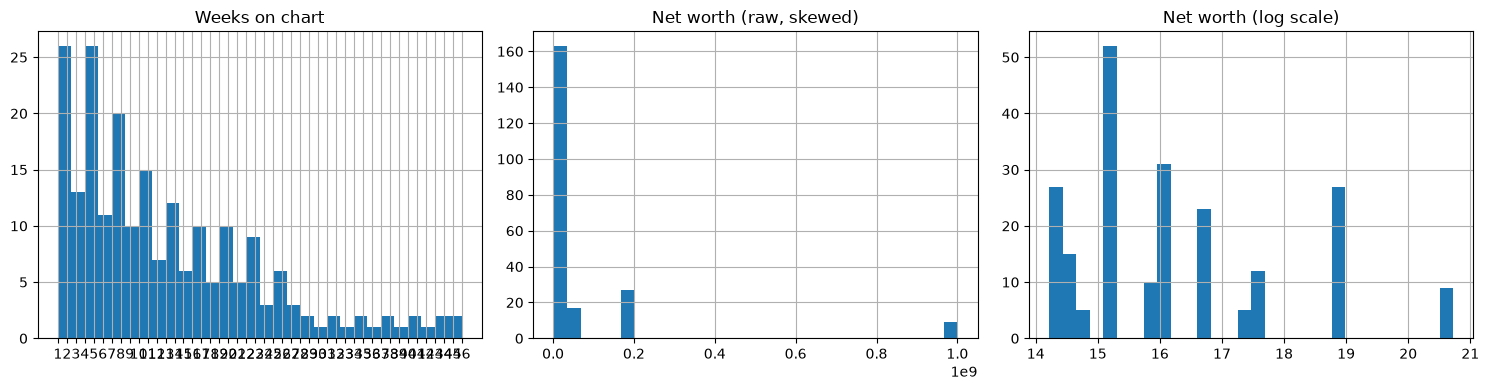

In [15]:
# Drop rows with no target; other gaps are imputed inside the model pipeline
df = df.dropna(subset=[TARGET]).copy()

# Net worth and playlist counts are heavily right-skewed, so log-transform them
df['log_net_worth'] = np.log1p(df['Networth'])
if 'num_playlists' in df.columns:
    df['log_playlists'] = np.log1p(df['num_playlists'])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df[TARGET].hist(ax=axes[0], bins=30)
axes[0].set_title('Weeks on chart')
df['Networth'].hist(ax=axes[1], bins=30)
axes[1].set_title('Net worth (raw, skewed)')
df['log_net_worth'].hist(ax=axes[2], bins=30)
axes[2].set_title('Net worth (log scale)')
plt.tight_layout()
plt.show()

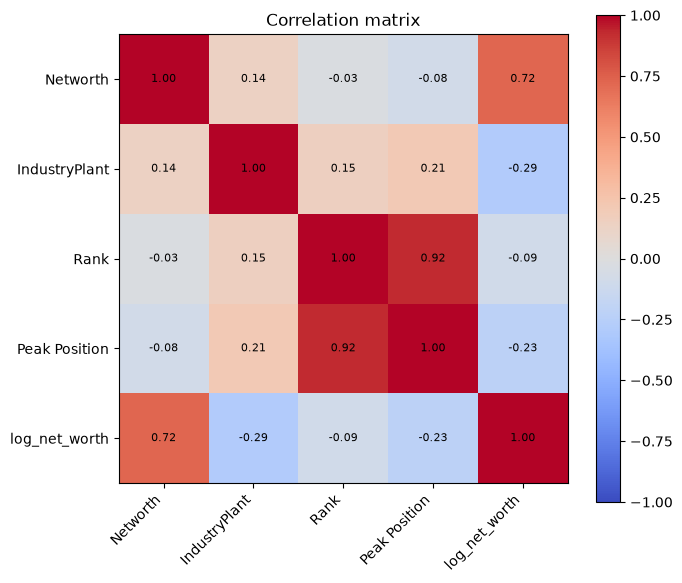

In [16]:
numeric_cols = df.select_dtypes(include='number').columns
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im)
ax.set_title('Correlation matrix')
plt.tight_layout()
plt.show()

In [18]:
INCLUDE_CONTROLS = True   # set to False to test only connections + net worth

FEATURES = ['IndustryPlant', 'log_net_worth']
if INCLUDE_CONTROLS:
    if 'major_label' in df.columns:
        FEATURES.append('major_label')
    if 'log_playlists' in df.columns:
        FEATURES.append('log_playlists')

print('Features used:', FEATURES)

X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f'Train: {len(X_train)} rows | Test: {len(X_test)} rows')

Features used: ['IndustryPlant', 'log_net_worth']
Train: 172 rows | Test: 44 rows


In [19]:
def make_pipeline(model):
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('model', model),
    ])

models = {
    'Baseline (mean)': make_pipeline(DummyRegressor(strategy='mean')),
    'Linear Regression': make_pipeline(LinearRegression()),
    'Random Forest': make_pipeline(RandomForestRegressor(
        n_estimators=300, max_depth=6, min_samples_leaf=5, random_state=RANDOM_STATE)),
    'Gradient Boosting': make_pipeline(GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE)),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, pipe in models.items():
    # Cross-validated R2 on the training set (more stable than a single split)
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='r2')

    # Fit on all training data, evaluate once on the held-out test set
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    rows.append({
        'Model': name,
        'CV R2 (mean)': cv_r2.mean(),
        'CV R2 (std)': cv_r2.std(),
        'Test MAE': mean_absolute_error(y_test, pred),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'Test R2': r2_score(y_test, pred),
    })

results = pd.DataFrame(rows).set_index('Model').round(3)
results

,CV R2 (mean),CV R2 (std),Test MAE,Test RMSE,Test R2
Model,,,,,
Baseline (mean),-0.025,0.018,7.156,9.219,-0.012
Linear Regression,0.039,0.138,6.896,8.794,0.079
Random Forest,0.182,0.188,5.840,7.501,0.330
Gradient Boosting,0.297,0.150,4.839,6.687,0.468


RMSE improvement over baseline (%):
Model
Linear Regression     4.6
Random Forest        18.6
Gradient Boosting    27.5
Name: Test RMSE, dtype: float64


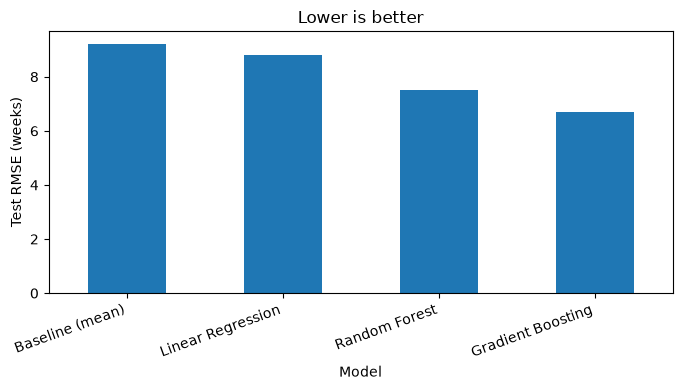

In [20]:
# How much does each model improve on the baseline?
base_rmse = results.loc['Baseline (mean)', 'Test RMSE']
improvement = ((base_rmse - results['Test RMSE']) / base_rmse * 100).round(1)
print('RMSE improvement over baseline (%):')
print(improvement.drop('Baseline (mean)'))

fig, ax = plt.subplots(figsize=(7, 4))
results['Test RMSE'].plot(kind='bar', ax=ax)
ax.set_ylabel('Test RMSE (weeks)')
ax.set_title('Lower is better')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

Linear regression coefficients (weeks per 1 std dev change):
IndustryPlant   -3.366
log_net_worth   -3.068
dtype: float64


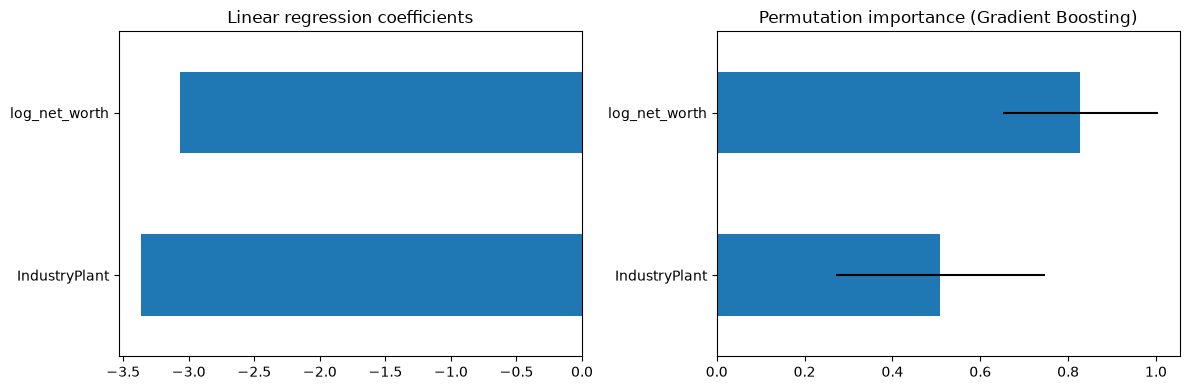

In [21]:
# Linear regression coefficients (features are standardized, so sizes are comparable)
lin = models['Linear Regression'].named_steps['model']
coefs = pd.Series(lin.coef_, index=FEATURES).sort_values()
print('Linear regression coefficients (weeks per 1 std dev change):')
print(coefs.round(3))

# Permutation importance on the test set for the best tree model
best_name = 'Random Forest' if results.loc['Random Forest', 'Test R2'] >= results.loc['Gradient Boosting', 'Test R2'] else 'Gradient Boosting'
best_pipe = models[best_name]
perm = permutation_importance(best_pipe, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE, scoring='r2')
perm_df = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
coefs.plot(kind='barh', ax=axes[0], title='Linear regression coefficients')
perm_df.plot(kind='barh', ax=axes[1], xerr=pd.Series(perm.importances_std, index=FEATURES).reindex(perm_df.index), title=f'Permutation importance ({best_name})')
plt.tight_layout()
plt.show()

UFuncTypeError: ufunc 'less' did not contain a loop with signature matching types (<class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.StrDType'>) -> None

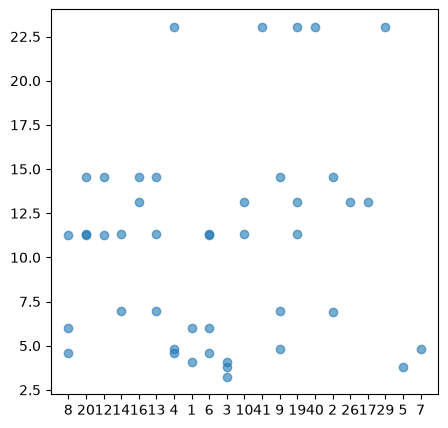

In [35]:
# Predicted vs actual for the best model
pred_best = best_pipe.predict(X_test)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_test, pred_best, alpha=0.6)
lims = [min(y_test.min(), pred_best.min()), max(y_test.max(), pred_best.max())]
ax.plot(lims, lims, 'r--')
ax.set_xlabel('Actual weeks on chart')
ax.set_ylabel('Predicted weeks on chart')
ax.set_title(f'{best_name}: predicted vs actual')
plt.tight_layout()
plt.show()